# Prepare MISR data

This notebook uses the MISR package to convert MISR hdf files into an xarray format. Not every piece of information contained in the hdf file is transferred to the xarray. Only the pieces relavant to AT3D.

In [1]:
# conda env 'misr'
import MisrToolkit as mtk
from pathlib import Path
import sys

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

In [2]:
from src.MISR import hdf2xr, grp2xr

In [12]:
## Set data path
misr_data_dir = PROJECT_ROOT / 'data' / 'raw' / 'MISR'

## Specify MISR parameters
path = 117
orbit = 105254
cameras = ['DF', 'CF', 'BF', 'AF', 'AN', 'AA', 'BA', 'CA', 'DA']

## Define geographic region
center_lat = 19.266267063099104
center_lon = 119.72428415176724
region = mtk.MtkRegion(center_lat, center_lon, 8.8*3, 8.8*3, "km")

# ## Load MISR red band images
# imagery = grp2xr(misr_data_dir, path, orbit, cameras, region)

# ## Load geometric parameters
# gmp_file = misr_data_dir / f'MISR_AM1_GP_GMP_P{path}_O{orbit}_F03_0013.hdf'
# field_list_solar = ['SolarZenith', 'SolarAzimuth']
# field_list_vza = [f'{c.lower().capitalize()}Zenith' for c in cameras]
# field_list_vaa = [f'{c.lower().capitalize()}Azimuth' for c in cameras]
# field_list = field_list_solar + field_list_vza + field_list_vaa
# gmp = hdf2xr(gmp_file, 'GeometricParameters', field_list, region)

# ## Load CTH
tc_cloud_file = misr_data_dir / f'MISR_AM1_TC_CLOUD_P{path:03d}_O{orbit:06d}_F01_0001.hdf'
cth = hdf2xr(tc_cloud_file, 'Stereo_1.1_km', ['CloudTopHeight', 'CloudMotionCrossTrack', 'CloudMotionCrossTrackHeading', 'StereoDerivedCloudMask'], region)

## Load CMV
cmv = hdf2xr(tc_cloud_file, 'Motion_17.6_km', ['CloudTopHeightOfMotion', 'CloudMotionNorthward', 'CloudMotionEastward'], region)
cmv2 = hdf2xr(tc_cloud_file, 'Stereo_WithoutWindCorrection_1.1_km', ['CloudTopHeight_WithoutWindCorrection', 'CloudMotionCrossTrack_WithoutWindCorrection', 'CloudMotionCrossTrackHeading_WithoutWindCorrection'], region)

In [13]:
cmv

<xarray.Dataset>
Dimensions:                 (som_x: 3, som_y: 3)
Coordinates:
  * som_x                   (som_x) float64 1.796e+07 1.798e+07 1.799e+07
  * som_y                   (som_y) float64 2.018e+05 2.194e+05 2.370e+05
Data variables:
    lat                     (som_x, som_y) float64 19.44 19.42 ... 19.11 19.09
    lon                     (som_x, som_y) float64 119.6 119.7 ... 119.7 119.9
    gamma                   (som_x, som_y) float64 1.654 1.655 ... 1.655 1.656
    CloudTopHeightOfMotion  (som_x, som_y) float32 521.1 531.3 ... 591.1 513.6
    CloudMotionNorthward    (som_x, som_y) float32 1.202 1.466 ... 1.004 0.09489
    CloudMotionEastward     (som_x, som_y) float32 1.594 1.463 ... -0.07763
Attributes:
    path:         117
    orbit:        105254
    block_range:  (75, 75)
    resolution:   17600
    regionID:     P117_R17600_X17959150_17994350_Y0201850_0237050

In [14]:
cmv2

<xarray.Dataset>
Dimensions:                                             (som_x: 48, som_y: 48)
Coordinates:
  * som_x                                               (som_x) float64 1.795...
  * som_y                                               (som_y) float64 1.936...
Data variables:
    lat                                                 (som_x, som_y) float64 ...
    lon                                                 (som_x, som_y) float64 ...
    gamma                                               (som_x, som_y) float64 ...
    CloudTopHeight_WithoutWindCorrection                (som_x, som_y) int16 ...
    CloudMotionCrossTrack_WithoutWindCorrection         (som_x, som_y) float32 ...
    CloudMotionCrossTrackHeading_WithoutWindCorrection  (som_x, som_y) float32 ...
Attributes:
    path:         117
    orbit:        105254
    block_range:  (75, 75)
    resolution:   1100
    regionID:     P117_R01100_X17950900_18002600_Y0193600_0245300

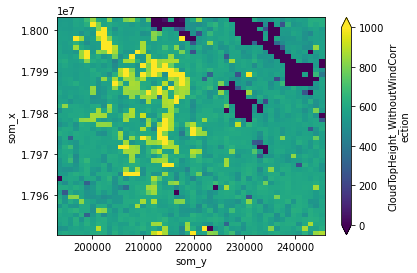

In [15]:
cmv2.CloudTopHeight_WithoutWindCorrection.plot(vmin=0,vmax=1000)

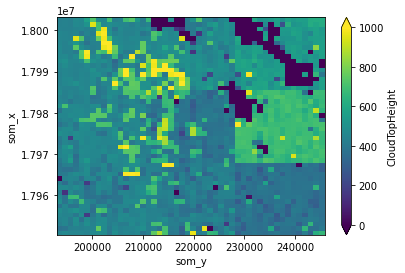

In [11]:
cth.CloudTopHeight.plot(vmin=0,vmax=1000)

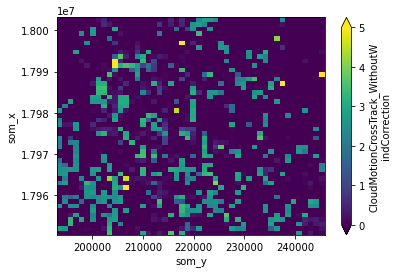

In [20]:
cmv2.CloudMotionCrossTrack_WithoutWindCorrection.plot(vmin=0,vmax=5)

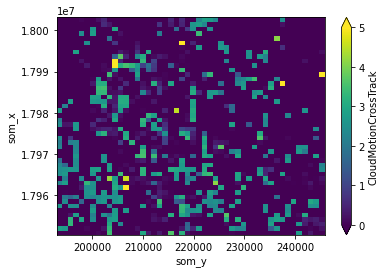

In [21]:
cth.CloudMotionCrossTrack.plot(vmin=0, vmax=5)

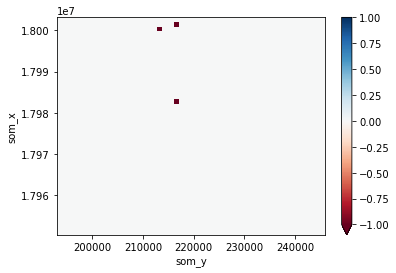

In [25]:
(cth.CloudMotionCrossTrack - cmv2.CloudMotionCrossTrack_WithoutWindCorrection).plot(vmin=-1, vmax=1, cmap='RdBu')

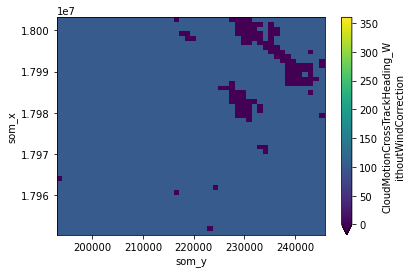

In [29]:
cmv2.CloudMotionCrossTrackHeading_WithoutWindCorrection.plot(vmin=0,vmax=360)

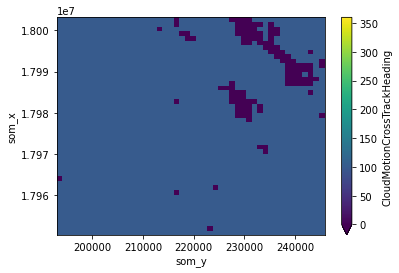

In [30]:
cth.CloudMotionCrossTrackHeading.plot(vmin=0, vmax=360)